<a href="https://colab.research.google.com/github/Gayathri-sp18/Social_Media_Engagement_Analytics/blob/main/Social_Media_Engagement_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


#**Social Media Engagement Analytics Using Python**



##**Data Import & Setup**

####**Import CSV using Pandas**


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import plotly.express as px

df = pd.read_csv("social_media_engagement_5000.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (5000, 19)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


####**Check/convert data types**

In [ ]:

print("First five rows:")
display(df.head())

print("Last five rows:")
display(df.tail())

print("Dataset shape:", df.shape)

print("Column names:")
print(df.columns.tolist())

print("Dataset information:")
df.info()

print("Data types:")
print(df.dtypes)

print("Summary statistics:")
display(df.describe(include="all"))

First five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


Last five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


Dataset shape: (5000, 19)
Column names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_ti

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
count,5000.000000,4850.000000,4850,5000,5000.000000,5000,5000,4850.000000,4850.000000,4850.000000,5000.000000,5000.000000,5000,5000.000000,5000,5000,4850,5000,5000.000000
unique,NaN,NaN,3,10,NaN,4,8,NaN,NaN,NaN,NaN,NaN,729,NaN,2,3,3,761,NaN
top,NaN,NaN,Male,India,NaN,reel,fitness,NaN,NaN,NaN,NaN,NaN,26-12-2023,NaN,False,mobile,positive,#tech,NaN
freq,NaN,NaN,1699,535,NaN,1283,675,NaN,NaN,NaN,NaN,NaN,16,NaN,4517,1684,2363,201,NaN
mean,54561.890800,38.454021,NaN,NaN,548042.909000,NaN,NaN,10107.043711,1502.195670,1002.629485,4014.503200,50013.732800,NaN,393698.224800,NaN,NaN,NaN,NaN,0.964356
std,26090.370121,14.912381,NaN,NaN,260646.957267,NaN,NaN,5789.819252,869.537889,579.615158,2308.096459,28844.939104,NaN,230927.884535,NaN,NaN,NaN,NaN,5.318029
min,10055.000000,13.000000,NaN,NaN,100068.000000,NaN,NaN,10.000000,0.000000,0.000000,0.000000,105.000000,NaN,87.000000,NaN,NaN,NaN,NaN,0.006363
25%,32309.500000,26.000000,NaN,NaN,322543.500000,NaN,NaN,5068.500000,760.000000,498.000000,2017.750000,24988.250000,NaN,194480.000000,NaN,NaN,NaN,NaN,0.145781
50%,54374.500000,38.000000,NaN,NaN,548077.500000,NaN,NaN,10105.500000,1497.000000,1012.000000,4034.500000,49934.500000,NaN,388982.000000,NaN,NaN,NaN,NaN,0.253896
75%,77180.500000,51.000000,NaN,NaN,771574.500000,NaN,NaN,15115.000000,2256.000000,1501.000000,6020.250000,74662.250000,NaN,589744.250000,NaN,NaN,NaN,NaN,0.504794


####**Convert date columns to datetime**

In [ ]:

print([
    col for col in df.columns
    if "date" in col.lower() or "time" in col.lower()
])


['watch_time_sec', 'sentiment']


In [ ]:

df["posted_at"] = pd.to_datetime(
    df["posted_at"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Valid dates:", df["posted_at"].notna().sum())
print("Invalid or missing dates:", df["posted_at"].isna().sum())
print("Date range:", df["posted_at"].min(), "to", df["posted_at"].max())

Valid dates: 5000
Invalid or missing dates: 0
Date range: 2022-01-01 00:00:00 to 2023-12-31 00:00:00


In [ ]:

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)


Numeric columns: ['user_id', 'age', 'post_id', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'follower_count', 'engagement_rate']
Categorical columns: ['gender', 'country', 'post_type', 'post_category', 'is_verified', 'device_type', 'sentiment', 'hashtags']


####**Use NumPy arrays for basic array operations**

In [ ]:

numeric_array = df.select_dtypes(include=np.number).to_numpy()

print("NumPy array:")
print(numeric_array[:5])

print("Array shape:", numeric_array.shape)
print("Array dimensions:", numeric_array.ndim)
print("Array size:", numeric_array.size)

if numeric_array.size > 0:
    print("Mean of numeric values:", np.nanmean(numeric_array))
    print("Maximum value:", np.nanmax(numeric_array))
    print("Minimum value:", np.nanmin(numeric_array))


NumPy array:
[[2.57950000e+04 4.30000000e+01 4.96713000e+05 7.01100000e+03
  3.54000000e+02 1.15700000e+03 5.72600000e+03 4.46500000e+04
  8.17340000e+04 1.90862262e-01]
 [1.08600000e+04 3.30000000e+01 1.57326000e+05 1.17500000e+04
  2.60600000e+03 1.80700000e+03 5.94700000e+03 8.02160000e+04
  5.96300000e+03 2.01493468e-01]
 [8.68200000e+04 3.20000000e+01 1.09864000e+05 4.86200000e+03
  3.44000000e+02 9.55000000e+02 6.94600000e+03 4.48580000e+04
  5.01783000e+05 1.37344509e-01]
 [6.48860000e+04 5.10000000e+01 8.48877000e+05 5.35000000e+03
  1.08300000e+03 1.04900000e+03 2.29000000e+02 7.04550000e+04
  4.80212000e+05 1.06195444e-01]
 [1.62650000e+04 3.40000000e+01 4.49706000e+05 1.26820000e+04
  2.73500000e+03 1.30000000e+03 4.79800000e+03 6.01900000e+03
  3.83936000e+05 2.77737166e+00]]
Array shape: (5000, 10)
Array dimensions: 2
Array size: 50000
Mean of numeric values: 107550.91479312036
Maximum value: 999455.0
Minimum value: 0.0


##**Data Cleaning**

####**Cleaning Missing Data**

In [ ]:

print("Missing values using isnull():")
display(df.isnull().sum())

print("Missing values using isna():")
display(df.isna().sum())

print("Total missing values:", df.isna().sum().sum())

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

display(missing_summary)


Missing values using isnull():


,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


Missing values using isna():


,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


Total missing values: 900


,Missing Count,Missing Percentage
user_id,0,0.0
age,150,3.0
gender,150,3.0
country,0,0.0
post_id,0,0.0
post_type,0,0.0
post_category,0,0.0
likes,150,3.0
comments,150,3.0
shares,150,3.0


This tells you which columns contain missing values and what percentage of each column is missing

In [ ]:

before_rows = len(df)

df = df.dropna(how="all")

print("Completely empty rows removed:", before_rows - len(df))


Completely empty rows removed: 0


dropna(how="all") removes rows where every field is missing. It does not remove rows that have only one or two missing values.

In [ ]:

numeric_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in ["user_id", "post_id"]
]

for col in numeric_cols:
    median_value = df[col].median()

    if pd.notna(median_value):
        df[col] = df[col].fillna(median_value)

print("Missing numeric values handled using medians.")

Missing numeric values handled using medians.


The median is less affected by extreme values than the mean. This is a practical default for suitable numerical measurements, but do not use it for identifiers or where missingness has a special meaning.

In [ ]:
missing_summary = df.isnull().sum()

print("Columns with missing values:")
display(missing_summary[missing_summary > 0])

print("Total missing values:", df.isnull().sum().sum())

Columns with missing values:


,0
gender,150
sentiment,150


Total missing values: 300


In [ ]:

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

for col in categorical_cols:
    modes = df[col].mode(dropna=True)

    if not modes.empty:
        df[col] = df[col].fillna(modes.iloc[0])

print("Missing categorical values handled using the mode.")



Missing categorical values handled using the mode.


In [ ]:
print("Missing values remaining in each column:")
display(df.isnull().sum())

print("Total missing values remaining:", df.isnull().sum().sum())

Missing values remaining in each column:


,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


Total missing values remaining: 0


In [ ]:

fill_demo = pd.Series([10, np.nan, 20, np.nan, 30])

print("Original values:")
display(fill_demo)

print("Forward-filled values:")
display(fill_demo.ffill())

print("Backward-filled values:")
display(fill_demo.bfill())


Original values:


,0
0,10.0
1,NaN
2,20.0
3,NaN
4,30.0


Forward-filled values:


,0
0,10.0
1,10.0
2,20.0
3,20.0
4,30.0


Backward-filled values:


,0
0,10.0
1,20.0
2,20.0
3,30.0
4,30.0


This demonstrates both required methods without incorrectly filling the actual dataset using an arbitrary neighbouring post.

In [ ]:

demo_df = pd.DataFrame({
    "likes": [100, np.nan, 200],
    "comments": [10, 20, np.nan]
})

print("Original demonstration data:")
display(demo_df)

print("Rows after dropna():")
display(demo_df.dropna())

print("Missing values filled with zero:")
display(demo_df.fillna(0))


Original demonstration data:


,likes,comments
0,100.0,10.0
1,NaN,20.0
2,200.0,NaN


Rows after dropna():


,likes,comments
0,100.0,10.0


Missing values filled with zero:


,likes,comments
0,100.0,10.0
1,0.0,20.0
2,200.0,0.0


This small example demonstrates the two methods. Filling missing engagement measurements with zero is not automatically appropriate for the real dataset, because missing data does not necessarily mean zero engagement.

In [ ]:

display(df.isna().sum())


,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


####**Duplicate Handling**

In [ ]:

print("Duplicate rows before removal:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate rows after removal:", df.duplicated().sum())
print("Dataset shape after duplicate removal:", df.shape)


Duplicate rows before removal: 0
Duplicate rows after removal: 0
Dataset shape after duplicate removal: (5000, 19)


duplicated() identifies repeated rows, while drop_duplicates() removes repeated records.

####**Data Formatting**

In [ ]:

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Extra spaces removed from text values.")


Extra spaces removed from text values.


This removes leading and trailing spaces. We will standardize the sentiment labels separately.

In [ ]:

gender_col = next(
    (col for col in df.columns if col.lower().strip() == "gender"),
    None
)

if gender_col:
    print(df[gender_col].value_counts(dropna=False))
    print("Unique gender labels:", df[gender_col].unique())
else:
    print("No gender column found.")


gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64
Unique gender labels: ['Female' 'Male' 'Other']


In [ ]:

if gender_col:
    gender_mapping = {
        "m": "Male",
        "male": "Male",
        "f": "Female",
        "female": "Female",
        "non-binary": "Non-binary",
        "non binary": "Non-binary",
        "nonbinary": "Non-binary"
    }

    df[gender_col] = df[gender_col].apply(
        lambda x: gender_mapping.get(x.lower().strip(), x)
        if isinstance(x, str) else x
    )

    print("Standardized gender distribution:")
    display(df[gender_col].value_counts(dropna=False))


Standardized gender distribution:


,count
gender,
Male,1849
Other,1581
Female,1570


This preserves unrecognized labels rather than automatically assigning them to a different category.

In [ ]:


count_metrics = [
    "likes",
    "comments",
    "shares",
    "impression_count",
    "follower_count"
]

other_metrics = [
    "watch_time_sec",
    "engagement_rate"
]

for col in count_metrics + other_metrics:
    if col in df.columns:
        print(f"\nColumn: {col}")
        print("Minimum:", df[col].min())
        print("Maximum:", df[col].max())
        print("Negative values:", (df[col] < 0).sum())




Column: likes
Minimum: 10.0
Maximum: 19998.0
Negative values: 0

Column: comments
Minimum: 0.0
Maximum: 2999.0
Negative values: 0

Column: shares
Minimum: 0.0
Maximum: 1999.0
Negative values: 0

Column: impression_count
Minimum: 105
Maximum: 99995
Negative values: 0

Column: follower_count
Minimum: 87
Maximum: 799533
Negative values: 0

Column: watch_time_sec
Minimum: 0
Maximum: 7998
Negative values: 0

Column: engagement_rate
Minimum: 0.006362909
Maximum: 191.5043478
Negative values: 0


For count metrics, negative values are generally invalid. For watch time, verify the unit and whether any negative values represent data errors. For engagement rate, confirm whether the dataset uses values such as 0.05 to represent 5%, or 5 to represent 5%.

####**Feature Cleaning**

In [ ]:

sentiment_col = next(
    (col for col in df.columns if col.lower().strip() == "sentiment"),
    None
)

if sentiment_col:
    df[sentiment_col] = df[sentiment_col].apply(
        lambda x: x.lower().strip() if isinstance(x, str) else x
    )

    print("Sentiment distribution after cleaning:")
    display(df[sentiment_col].value_counts(dropna=False))
else:
    print("No sentiment column found.")


Sentiment distribution after cleaning:


,count
sentiment,
positive,2513
neutral,1527
negative,960


This standardizes labels such as Positive, positive and POSITIVE to positive. Do not combine different sentiment categories unless they are genuinely equivalent.

In [ ]:

hashtag_candidates = ["hashtags", "caption", "text", "post_content"]

hashtag_col = next(
    (
        col for col in df.columns
        if col.lower().strip() in hashtag_candidates
    ),
    None
)

print("Selected hashtag/text column:", hashtag_col)


Selected hashtag/text column: hashtags


In [ ]:

if hashtag_col:
    df["hashtag_count"] = df[hashtag_col].apply(
        lambda x: len(re.findall(r"#\w+", x))
        if isinstance(x, str) else 0
    )

    display(df[[hashtag_col, "hashtag_count"]].head())
else:
    print(
        "No suitable text/hashtag column found. "
        "Inspect the dataset columns before creating hashtag_count."
    )


,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


##**Data Exploration using Pandas**

In [ ]:

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())
display(df.tail())

df.info()

display(df.describe(include="all").T)


Shape: (5000, 20)
Columns: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
user_id,5000.0,NaN,NaN,NaN,54561.8908,10055.0,32309.5,54374.5,77180.5,99963.0,26090.370121
age,5000.0,NaN,NaN,NaN,38.4404,13.0,26.0,38.0,51.0,64.0,14.687151
gender,5000,3,Male,1849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,5000,10,India,535,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_id,5000.0,NaN,NaN,NaN,548042.909,100068.0,322543.5,548077.5,771574.5,999455.0,260646.957267
post_type,5000,4,reel,1283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_category,5000,8,fitness,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,5000.0,NaN,NaN,NaN,10106.9974,10.0,5235.0,10105.5,14959.0,19998.0,5702.293017
comments,5000.0,NaN,NaN,NaN,1502.0398,0.0,792.0,1497.0,2235.25,2999.0,856.393312
shares,5000.0,NaN,NaN,NaN,1002.9106,0.0,511.0,1012.0,1483.0,1999.0,570.8552


In [ ]:

for col in df.select_dtypes(
    include=["object", "category", "bool"]
).columns:
    print(f"\nColumn: {col}")
    print("Unique values:", df[col].unique()[:20])
    print("Number of unique values:", df[col].nunique())
    display(df[col].value_counts(dropna=False).head(20))



Column: gender
Unique values: ['Female' 'Male' 'Other']
Number of unique values: 3


,count
gender,
Male,1849
Other,1581
Female,1570



Column: country
Unique values: ['Brazil' 'UK' 'France' 'Canada' 'Japan' 'Australia' 'India' 'UAE'
 'Germany' 'USA']
Number of unique values: 10


,count
country,
India,535
Canada,513
Brazil,504
UAE,503
USA,501
France,496
UK,493
Australia,493
Germany,490



Column: post_type
Unique values: ['image' 'reel' 'text' 'video']
Number of unique values: 4


...

,count
device_type,
mobile,1684
tablet,1658
desktop,1658



Column: sentiment
Unique values: ['negative' 'positive' 'neutral']
Number of unique values: 3


,count
sentiment,
positive,2513
neutral,1527
negative,960



Column: hashtags
Unique values: ['#foodie #travel #love' '#fitness' '#foodie' '#music #foodie #fun'
 '#travel' '#music' '#travel #music #fitness' '#music #fun #fitness'
 '#lifestyle #love' '#tech' '#fun #fashion #love' '#foodie #lifestyle'
 '#foodie #fashion' '#reels' '#foodie #fun #lifestyle'
 '#love #fashion #fitness' '#foodie #travel #fitness' '#foodie #fitness'
 '#fun' '#reels #fashion']
Number of unique values: 761


,count
hashtags,
#tech,201
#love,176
#fitness,174
#music,165
#fun,163
#travel,162
#fashion,159
#lifestyle,156
#reels,155


In [ ]:

numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(2))


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.00,-0.01,0.02,0.03,-0.03,0.01,-0.02,0.02,0.01,-0.00,-0.01
age,-0.01,1.00,-0.01,-0.04,-0.01,0.01,0.01,0.01,-0.02,0.01,0.01
post_id,0.02,-0.01,1.00,0.01,-0.01,0.00,0.02,-0.01,-0.00,0.01,0.01
likes,0.03,-0.04,0.01,1.00,-0.02,0.00,0.01,0.01,-0.02,0.09,-0.00
comments,-0.03,-0.01,-0.01,-0.02,1.00,0.01,-0.02,-0.01,-0.01,0.00,-0.02
shares,0.01,0.01,0.00,0.00,0.01,1.00,0.01,-0.01,-0.01,0.02,0.01
watch_time_sec,-0.02,0.01,0.02,0.01,-0.02,0.01,1.00,-0.00,0.00,-0.00,-0.02
impression_count,0.02,0.01,-0.01,0.01,-0.01,-0.01,-0.00,1.00,-0.02,-0.23,-0.00
follower_count,0.01,-0.02,-0.00,-0.02,-0.01,-0.01,0.00,-0.02,1.00,0.00,0.01
engagement_rate,-0.00,0.01,0.01,0.09,0.00,0.02,-0.00,-0.23,0.00,1.00,0.01


Correlation measures the strength and direction of linear relationships between numeric variables. A correlation does not prove that one variable causes another.

In [ ]:

if "post_type" in df.columns and "likes" in df.columns:
    avg_likes_by_post_type = (
        df.groupby("post_type")["likes"]
        .mean()
        .sort_values(ascending=False)
    )

    display(avg_likes_by_post_type)
else:
    print("Check the post_type and likes column names.")


,likes
post_type,
video,10188.600000
image,10104.865277
text,10100.148193
reel,10037.802416


In [ ]:
if "country" in df.columns and "impression_count" in df.columns:
    impressions_by_country = (
        df.groupby("country")["impression_count"]
        .mean()
        .sort_values(ascending=False)
    )

    display(impressions_by_country)
else:
    print("Check the country and impressions column names.")

,impression_count
country,
India,52462.386916
France,51727.673387
USA,51263.872255
UK,51119.393509
Japan,49616.135593
Brazil,49193.174603
UAE,48928.413519
Canada,48703.150097
Germany,48605.406122


In [ ]:

for group_col in ["post_type", "country", "sentiment"]:
    if group_col in df.columns:
        print(f"\nSummary by {group_col}:")

        available_metrics = [
            col for col in [
                "likes",
                "comments",
                "shares",
                "impression_count",
                "watch_time_sec",
                "engagement_rate",
                "follower_count",
                "engagement_score"
            ]
            if col in df.columns
        ]

        if available_metrics:
            display(
                df.groupby(group_col)[available_metrics]
                .mean(numeric_only=True)
                .round(2)
            )
        else:
            print("No matching metrics found.")



Summary by post_type:


,likes,comments,shares,impression_count,watch_time_sec,engagement_rate,follower_count
post_type,,,,,,,
image,10104.87,1525.24,1019.29,49727.42,3881.45,0.90,397485.11
reel,10037.80,1504.19,982.04,50462.60,4135.73,0.78,394466.32
text,10100.15,1499.11,1013.99,49987.22,4010.87,1.06,391436.56
video,10188.60,1479.16,996.83,49862.01,4026.67,1.12,391337.45



Summary by country:


,likes,comments,shares,impression_count,watch_time_sec,engagement_rate,follower_count
country,,,,,,,
Australia,10294.12,1485.80,1029.69,48346.38,4150.68,1.32,388979.83
Brazil,9886.69,1490.43,1008.86,49193.17,4049.21,1.54,407251.34
Canada,10063.07,1546.58,996.25,48703.15,4003.70,0.92,386956.91
France,10372.88,1478.70,1051.81,51727.67,3992.75,1.15,378857.87
Germany,10130.46,1531.83,973.38,48605.41,3976.38,0.76,396641.28
India,9962.47,1494.92,1035.32,52462.39,4016.84,0.66,416429.47
Japan,10088.86,1530.43,959.35,49616.14,3878.39,0.77,390841.44
UAE,10227.49,1541.21,989.08,48928.41,4007.82,1.11,402228.64
UK,9935.65,1463.04,985.68,51119.39,4118.69,0.85,378833.19



Summary by sentiment:


,likes,comments,shares,impression_count,watch_time_sec,engagement_rate,follower_count
sentiment,,,,,,,
negative,10208.10,1516.09,1007.31,50191.96,4054.64,1.04,397430.43
neutral,9923.19,1528.40,996.57,49515.97,4031.82,0.99,390568.45
positive,10180.06,1480.65,1005.09,50248.11,3988.65,0.92,394174.25


##**Data Wrangling**

In [ ]:

split_point = len(df) // 2

df_part1 = df.iloc[:split_point].copy()
df_part2 = df.iloc[split_point:].copy()

df_combined = pd.concat(
    [df_part1, df_part2],
    ignore_index=True
)

print("Original shape:", df.shape)
print("Combined shape:", df_combined.shape)

display(df_combined.head())


Original shape: (5000, 20)
Combined shape: (5000, 20)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [ ]:

required_metrics = ["likes", "comments", "shares"]

if all(metric in df.columns for metric in required_metrics):
    df["engagement_score"] = df[required_metrics].sum(axis=1)

    print("Engagement score created successfully.")

    display(
        df[required_metrics + ["engagement_score"]].head()
    )
else:
    print("Required columns are missing:", [
        col for col in required_metrics
        if col not in df.columns
    ])


Engagement score created successfully.


,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


In [ ]:

for metric in [
    "likes", "comments", "shares",
    "impression_count", "follower_count"
]:
    if metric in df.columns:
        df[f"log_{metric}"] = np.log1p(
            df[metric].clip(lower=0)
        )

print("Available log-transformed features:")
display(df.filter(regex="^log_").head())

Available log-transformed features:


,log_likes,log_comments,log_shares,log_impression_count,log_follower_count
0,8.855378,5.872118,7.054450,10.706632,11.311238
1,9.371694,7.865955,7.499977,11.292491,8.693497
2,8.489411,5.843544,6.862758,10.711280,13.125925
3,8.585039,6.988413,6.956545,11.162744,13.081985
4,9.448018,7.914252,7.170888,8.702843,12.858234


Log transformations can help visualize heavily skewed counts.

In [ ]:

group_columns = [
    col for col in ["post_type", "country", "sentiment"]
    if col in df.columns
]

metrics = [
    col for col in [
       "likes", "comments", "shares",
"impression_count", "watch_time_sec",
"engagement_rate", "follower_count",
"engagement_score"
    ]
    if col in df.columns
]

for group_col in group_columns:
    print(f"\nGrouped summary: {group_col}")

    summary = df.groupby(group_col)[metrics].agg(
        ["count", "mean", "median", "max"]
    )

    display(summary.round(2))



Grouped summary: post_type


likes                             comments                           \
          count      mean   median      max    count     mean  median     max   
post_type                                                                       
image      1247  10104.87  10105.5  19996.0     1247  1525.24  1497.0  2997.0   
reel       1283  10037.80  10105.5  19994.0     1283  1504.19  1497.0  2999.0   
text       1245  10100.15  10105.5  19998.0     1245  1499.11  1497.0  2999.0   
video      1225  10188.60  10105.5  19995.0     1225  1479.16  1481.0  2999.0   

          shares           ... engagement_rate         follower_count  \
           count     mean  ...          median     max          count   
post_type                  ...                                          
image       1247  1019.29  ...            0.26   92.83           1247   
reel        1283   982.04  ...            0.25   87.27           1283   
text        1245  1013.99  ...            0.25  191.50           1245   
video       1225   996.83  ...            0.25  121.93           1225   

                                       engagement_score                     \
                mean    median     max            count      mean   median   
post_type                                                                    
image      397485.11  398962.0  799076             1247  12649.39  12881.5   
reel       394466.32  389040.0  798674             1283  12524.03  12279.0   
text       391436.56  381781.0  799416             1245  12613.24  12457.0   
video      391337.45  387232.0  799533             1225  12664.59  12634.0   

                    
               max  
post_type           
image      24583.0  
reel       24423.0  
text       24383.0  
video      24680.0  

[4 rows x 32 columns]


Grouped summary: country


likes                              comments                   \
          count      mean    median      max    count     mean  median   
country                                                                  
Australia   493  10294.12  10105.50  19968.0      493  1485.80  1497.0   
Brazil      504   9886.69   9517.50  19986.0      504  1490.43  1497.0   
Canada      513  10063.07  10105.50  19979.0      513  1546.58  1507.0   
France      496  10372.88  10246.50  19996.0      496  1478.70  1484.0   
Germany     490  10130.46  10105.50  19889.0      490  1531.83  1537.0   
India       535   9962.47  10105.50  19998.0      535  1494.92  1497.0   
Japan       472  10088.86  10121.75  19992.0      472  1530.43  1511.0   
UAE         503  10227.49  10274.00  19995.0      503  1541.21  1498.0   
UK          493   9935.65   9893.00  19995.0      493  1463.04  1461.0   
USA         501  10122.36  10105.50  19994.0      501  1457.96  1485.0   

                  shares           ... engagement_rate         follower_count  \
              max  count     mean  ...          median     max          count   
country                            ...                                          
Australia  2999.0    493  1029.69  ...            0.27  121.93            493   
Brazil     2991.0    504  1008.86  ...            0.25  191.50            504   
Canada     2991.0    513   996.25  ...            0.26  105.75            513   
France     2999.0    496  1051.81  ...            0.24   67.51            496   
Germany    2999.0    490   973.38  ...            0.27   87.27            490   
India      2999.0    535  1035.32  ...            0.25   24.20            535   
Japan      2997.0    472   959.35  ...            0.26   29.19            472   
UAE        2995.0    503   989.08  ...            0.27   59.21            503   
UK         2984.0    493   985.68  ...            0.24   61.18            493   
USA        2995.0    501   995.14  ...            0.24   21.87            501   

                                       engagement_score                      \
                mean    median     max            count      mean    median   
country                                                                       
Australia  388979.83  379512.0  798116              493  12809.62  13030.00   
Brazil     407251.34  401827.0  799076              504  12385.98  11879.25   
Canada     386956.91  395429.0  797444              513  12605.89  12450.00   
France     378857.87  381785.5  794558              496  12903.38  13314.00   
Germany    396641.28  384267.5  796883              490  12635.66  12612.50   
India      416429.47  426952.0  798674              535  12492.70  12543.50   
Japan      390841.44  390319.5  799416              472  12578.65  12593.25   
UAE        402228.64  400226.0  799533              503  12757.78  12987.50   
UK         378833.19  369021.0  797881              493  12384.37  12107.00   
USA        387904.33  378404.0  797733              501  12575.46  12380.00   

                    
               max  
country             
Australia  23566.0  
Brazil     24583.0  
Canada     24423.0  
France     24203.0  
Germany    23641.0  
India      24486.0  
Japan      24090.0  
UAE        24509.0  
UK         24680.0  
USA        24383.0  

[10 rows x 32 columns]


Grouped summary: sentiment


likes                             comments                           \
          count      mean   median      max    count     mean  median     max   
sentiment                                                                       
negative    960  10208.10  10105.5  19976.0      960  1516.09  1497.0  2999.0   
neutral    1527   9923.19   9914.0  19995.0     1527  1528.40  1497.0  2999.0   
positive   2513  10180.06  10105.5  19998.0     2513  1480.65  1497.0  2999.0   

          shares           ... engagement_rate         follower_count  \
           count     mean  ...          median     max          count   
sentiment                  ...                                          
negative     960  1007.31  ...            0.26   68.69            960   
neutral     1527   996.57  ...            0.25  121.93           1527   
positive    2513  1005.09  ...            0.25  191.50           2513   

                                       engagement_score                     \
                mean    median     max            count      mean   median   
sentiment                                                                    
negative   397430.43  398746.5  798116              960  12731.50  12578.5   
neutral    390568.45  395520.0  799533             1527  12448.16  12244.0   
positive   394174.25  385165.0  799416             2513  12665.80  12691.5   

                    
               max  
sentiment           
negative   24680.0  
neutral    24423.0  
positive   24583.0  

[3 rows x 32 columns]

##**Statistical Analysis**

In [ ]:

stat_metrics = [
    "likes", "comments", "shares",
    "watch_time_sec", "engagement_rate", "follower_count"
]

stat_columns = [
    col for col in stat_metrics
    if col in df.columns
]

statistics = {}

for col in stat_columns:
    series = df[col].dropna()

    if len(series) > 0:
        mode_values = series.mode().tolist()

        statistics[col] = {
            "Mean": series.mean(),
            "Median": series.median(),
            "Mode": mode_values,
            "Standard Deviation": series.std(),
            "Variance": series.var(),
            "25th Percentile": series.quantile(0.25),
            "50th Percentile": series.quantile(0.50),
            "75th Percentile": series.quantile(0.75),
            "90th Percentile": series.quantile(0.90),
            "Minimum": series.min(),
            "Maximum": series.max(),
            "Skewness": series.skew(),
            "Kurtosis": series.kurt()
        }

statistics_df = pd.DataFrame(statistics).T

display(statistics_df.round(2))


,Mean,Median,Mode,Standard Deviation,Variance,25th Percentile,50th Percentile,75th Percentile,90th Percentile,Minimum,Maximum,Skewness,Kurtosis
likes,10106.9974,10105.5,[10105.5],5702.293017,32516145.653824,5235.0,10105.5,14959.0,18016.3,10.0,19998.0,-0.006894,-1.149992
comments,1502.0398,1497.0,[1497.0],856.393312,733409.504917,792.0,1497.0,2235.25,2695.1,0.0,2999.0,0.003802,-1.144375
shares,1002.9106,1012.0,[1012.0],570.8552,325875.65934,511.0,1012.0,1483.0,1795.1,0.0,1999.0,-0.014654,-1.146857
watch_time_sec,4014.5032,4034.5,"[916, 2145, 4360, 7003, 7688]",2308.096459,5327309.264243,2017.75,4034.5,6020.25,7212.1,0,7998,-0.018196,-1.195652
engagement_rate,0.964356,0.253896,"[0.006362909, 0.007420223, 0.012675682, 0.0126...",5.318029,28.281435,0.145781,0.253896,0.504794,1.2012,0.006363,191.504348,18.781271,482.991739
follower_count,393698.2248,388982.0,[497502],230927.884535,53327687855.630234,194480.0,388982.0,589744.25,717755.9,87,799533,0.041118,-1.189474


To interpret these statistics
- Mean: average value.
- Median: middle value after sorting.
- Mode: most frequently occurring value; a column can have multiple modes.
- Standard deviation: how spread out the values are around the mean.
- Variance: squared measure of dispersion.
- Percentiles: values below which a given percentage of observations falls.
- Skewness: indicates asymmetry in a distribution.
- Kurtosis: describes aspects of distribution tails and extreme values.

##**Data Visualization**

In [ ]:

def find_column(*names):
    lookup = {
        col.lower().strip(): col
        for col in df.columns
    }

    for name in names:
        if name.lower().strip() in lookup:
            return lookup[name.lower().strip()]

    return None


likes_col = find_column("likes")
comments_col = find_column("comments")
shares_col = find_column("shares")
impressions_col = find_column("impression_count", "impressions")
engagement_col = find_column("engagement_rate")
followers_col = find_column("follower_count", "followers")
age_col = find_column("age")
gender_col = find_column("gender")
post_type_col = find_column("post_type", "post type")
category_col = find_column("post_category", "category", "content_category")
country_col = find_column("country")
sentiment_col = find_column("sentiment")
device_col = find_column("device_type", "device")
verified_col = find_column("verified", "is_verified")
watch_time_col = find_column("watch_time_sec", "watch_time")
date_col = find_column("posted_at")

if date_col is not None:
    df[date_col] = pd.to_datetime(
        df[date_col],
        format="%d-%m-%Y",
        errors="coerce"
    )

print("Detected columns:")

for name, value in {
    "likes": likes_col,
    "comments": comments_col,
    "shares": shares_col,
    "impressions": impressions_col,
    "engagement_rate": engagement_col,
    "followers": followers_col,
    "age": age_col,
    "gender": gender_col,
    "post_type": post_type_col,
    "category": category_col,
    "country": country_col,
    "sentiment": sentiment_col,
    "device": device_col,
    "verified": verified_col,
    "watch_time": watch_time_col,
    "date": date_col
}.items():
    print(f"{name}: {value}")


Detected columns:
likes: likes
comments: comments
shares: shares
impressions: impression_count
engagement_rate: engagement_rate
followers: follower_count
age: age
gender: gender
post_type: post_type
category: post_category
country: country
sentiment: sentiment
device: device_type
verified: is_verified
watch_time: watch_time_sec
date: posted_at


Purpose: Checks whether posts with more impressions also tend to receive more likes.

In [ ]:
print("Date column:", date_col)
print("Likes column:", likes_col)


Date column: posted_at
Likes column: likes


In [ ]:
print(df.columns.tolist())

['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count', 'engagement_score', 'log_likes', 'log_comments', 'log_shares', 'log_impression_count', 'log_follower_count']


##**Data Visualization**

##**Matplotlib**

###**Line chart** — *daily engagement trend*

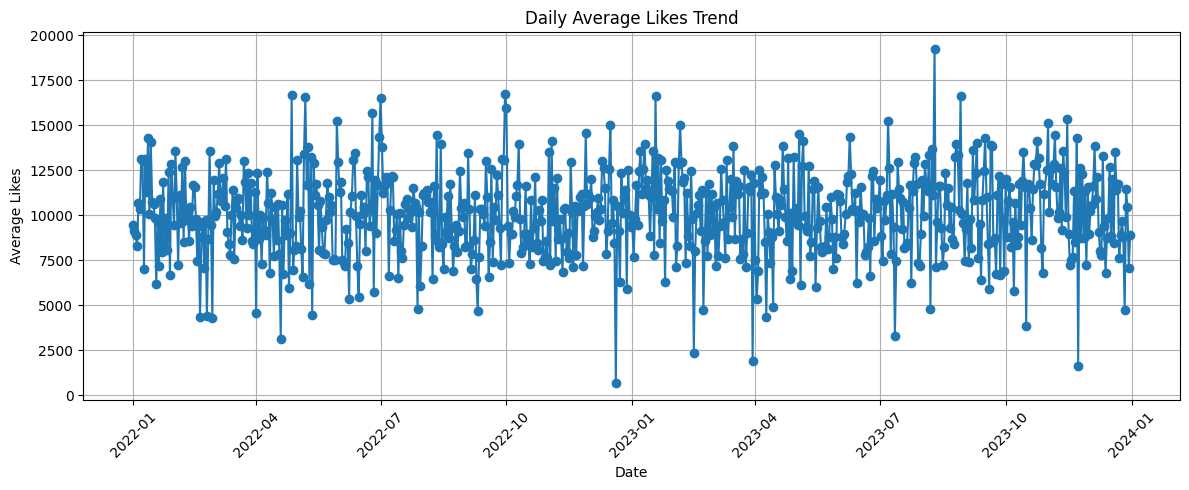

In [ ]:
line_df = df.dropna(subset=[date_col]).copy()

line_df["analysis_date"] = line_df[date_col].dt.date

daily_engagement = (
    line_df.groupby("analysis_date")["likes"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(
    daily_engagement.index,
    daily_engagement.values,
    marker="o"
)

plt.xlabel("Date")
plt.ylabel("Average Likes")
plt.title("Daily Average Likes Trend")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

###**Scatter plot** — *Likes vs. Impressions*

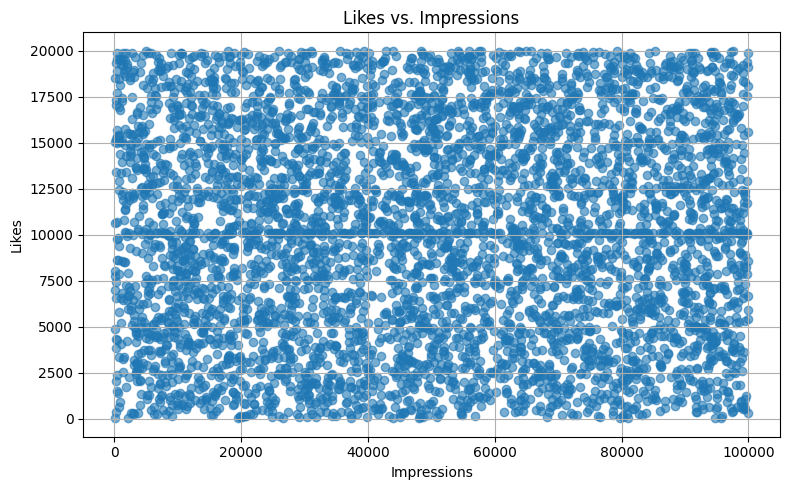

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["impression_count"], df["likes"], alpha=0.6)
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.title("Likes vs. Impressions")
plt.grid(True)
plt.tight_layout()
plt.show()

###**Bar chart** — *Number of posts by category*

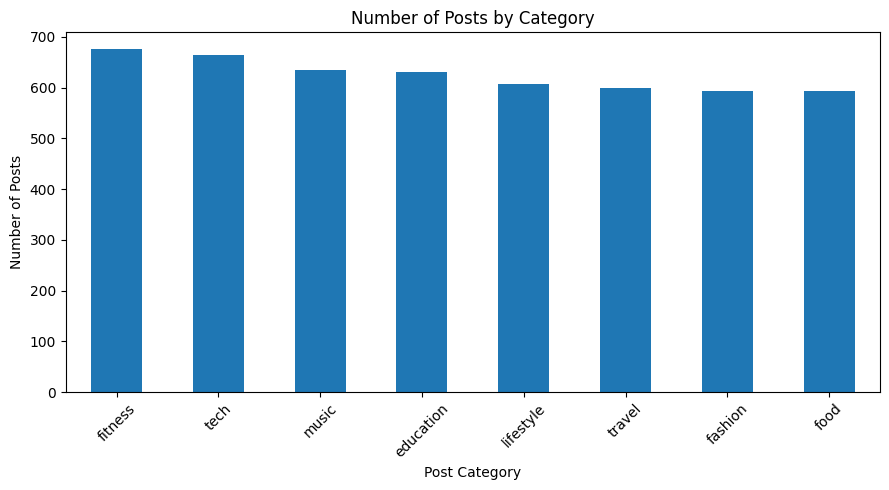

In [ ]:
plt.figure(figsize=(9, 5))
df["post_category"].value_counts().plot(kind="bar")
plt.xlabel("Post Category")
plt.ylabel("Number of Posts")
plt.title("Number of Posts by Category")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

###**Pie chart** — *Gender distribution*

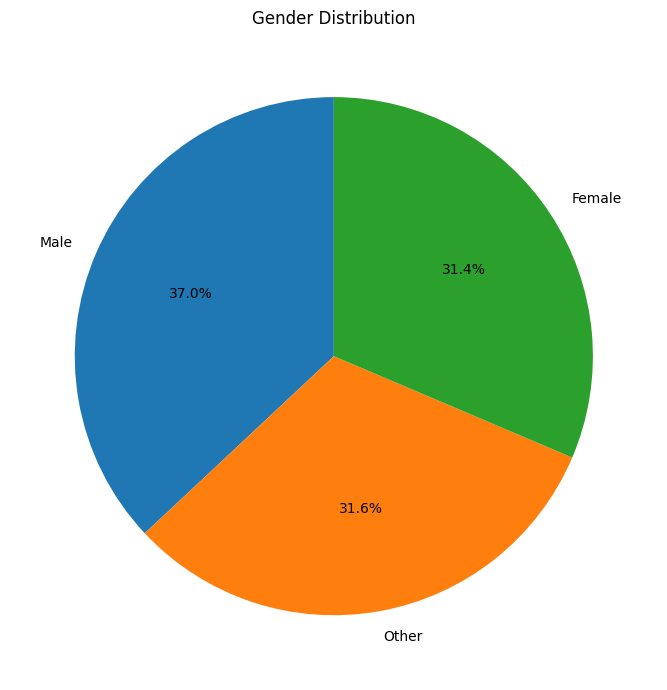

In [ ]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Gender Distribution")
plt.tight_layout()
plt.show()

###**Histogram** — *Age distribution*

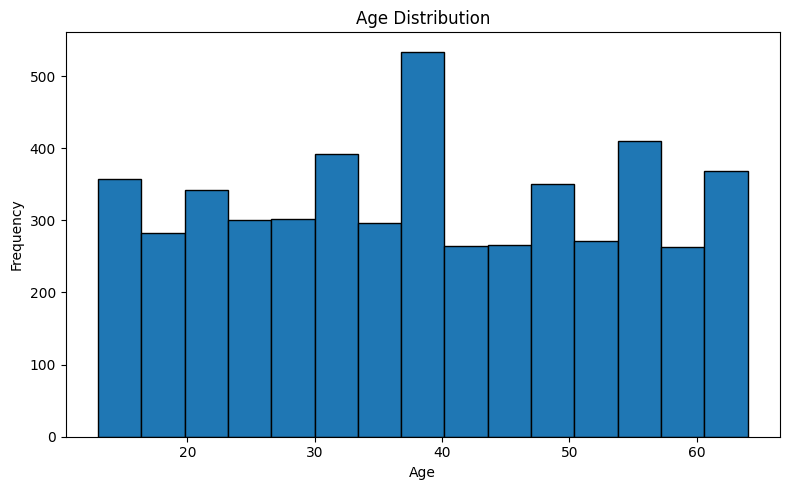

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["age"].dropna(), bins=15, edgecolor="black")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution")
plt.tight_layout()
plt.show()

###**Box plot** — *Engagement rate*

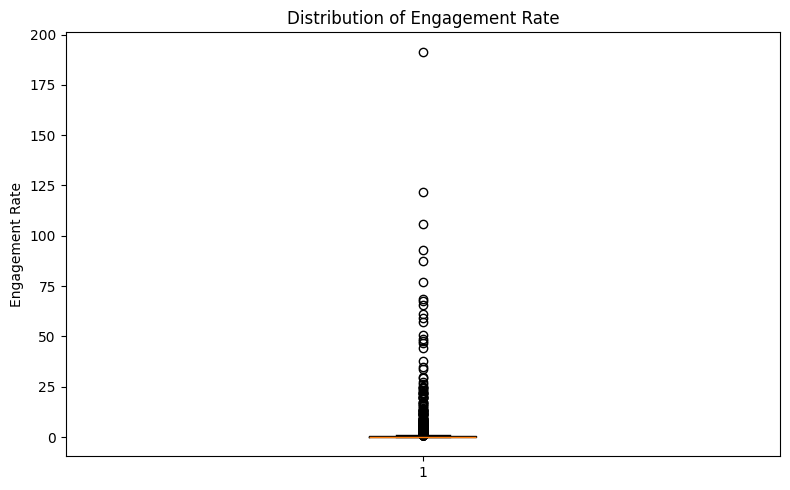

In [ ]:
plt.figure(figsize=(8, 5))
plt.boxplot(df["engagement_rate"].dropna())
plt.ylabel("Engagement Rate")
plt.title("Distribution of Engagement Rate")
plt.tight_layout()
plt.show()

##**Seaborn visualizations**

###**Count plot** — *Posts by post type*

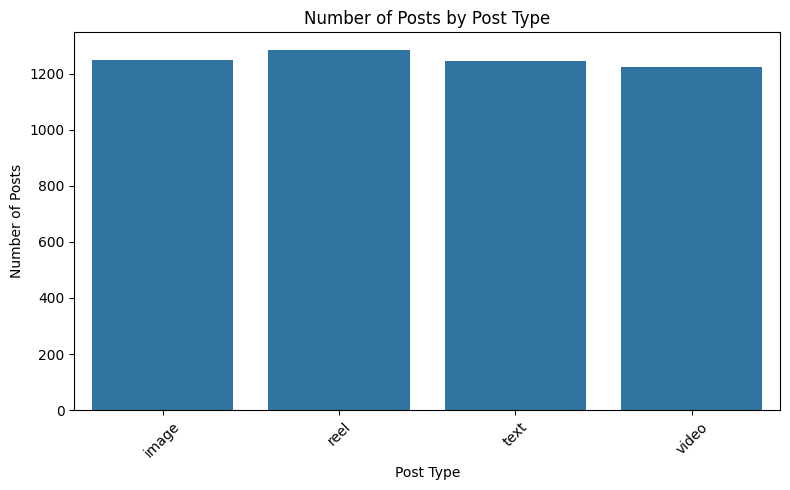

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="post_type")
plt.xlabel("Post Type")
plt.ylabel("Number of Posts")
plt.title("Number of Posts by Post Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

###**Bar plot** — *Average likes by category*

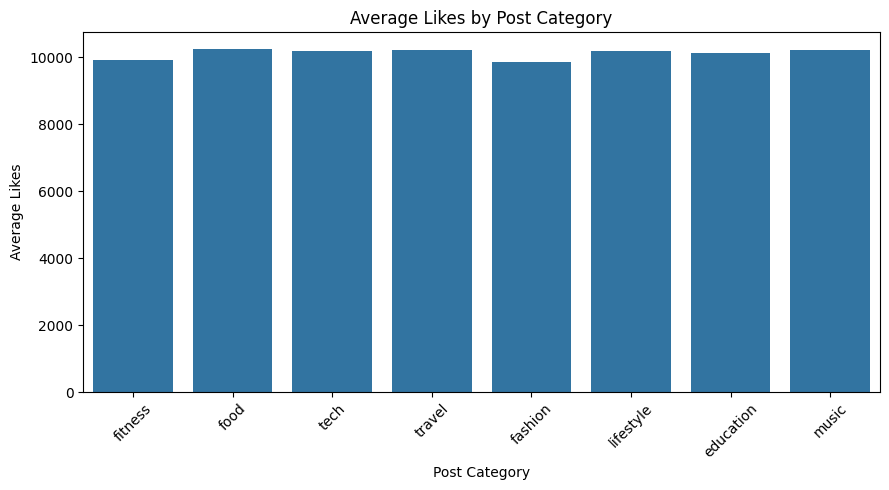

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="post_category",
    y="likes",
    errorbar=None
)

plt.xlabel("Post Category")
plt.ylabel("Average Likes")
plt.title("Average Likes by Post Category")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

###**Violin plot** — *Followers by sentiment*

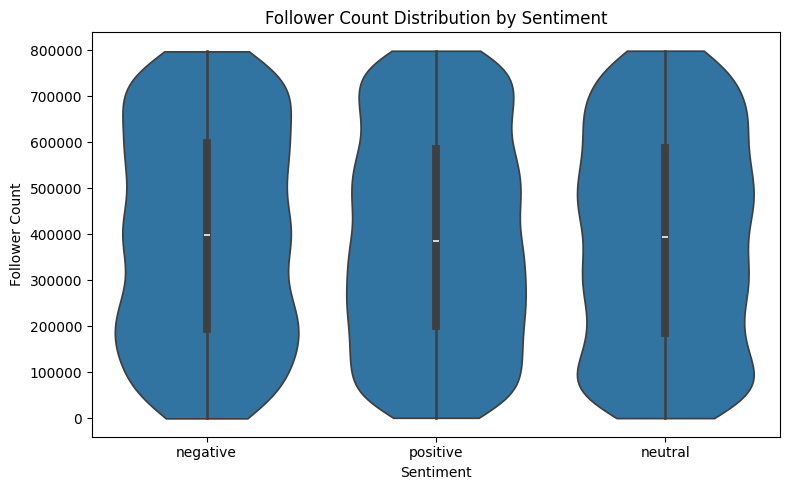

In [ ]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="sentiment",
    y="follower_count",
    cut=0
)

plt.xlabel("Sentiment")
plt.ylabel("Follower Count")
plt.title("Follower Count Distribution by Sentiment")
plt.tight_layout()
plt.show()

###**Pair plot** — *Relationships between numerical variables*

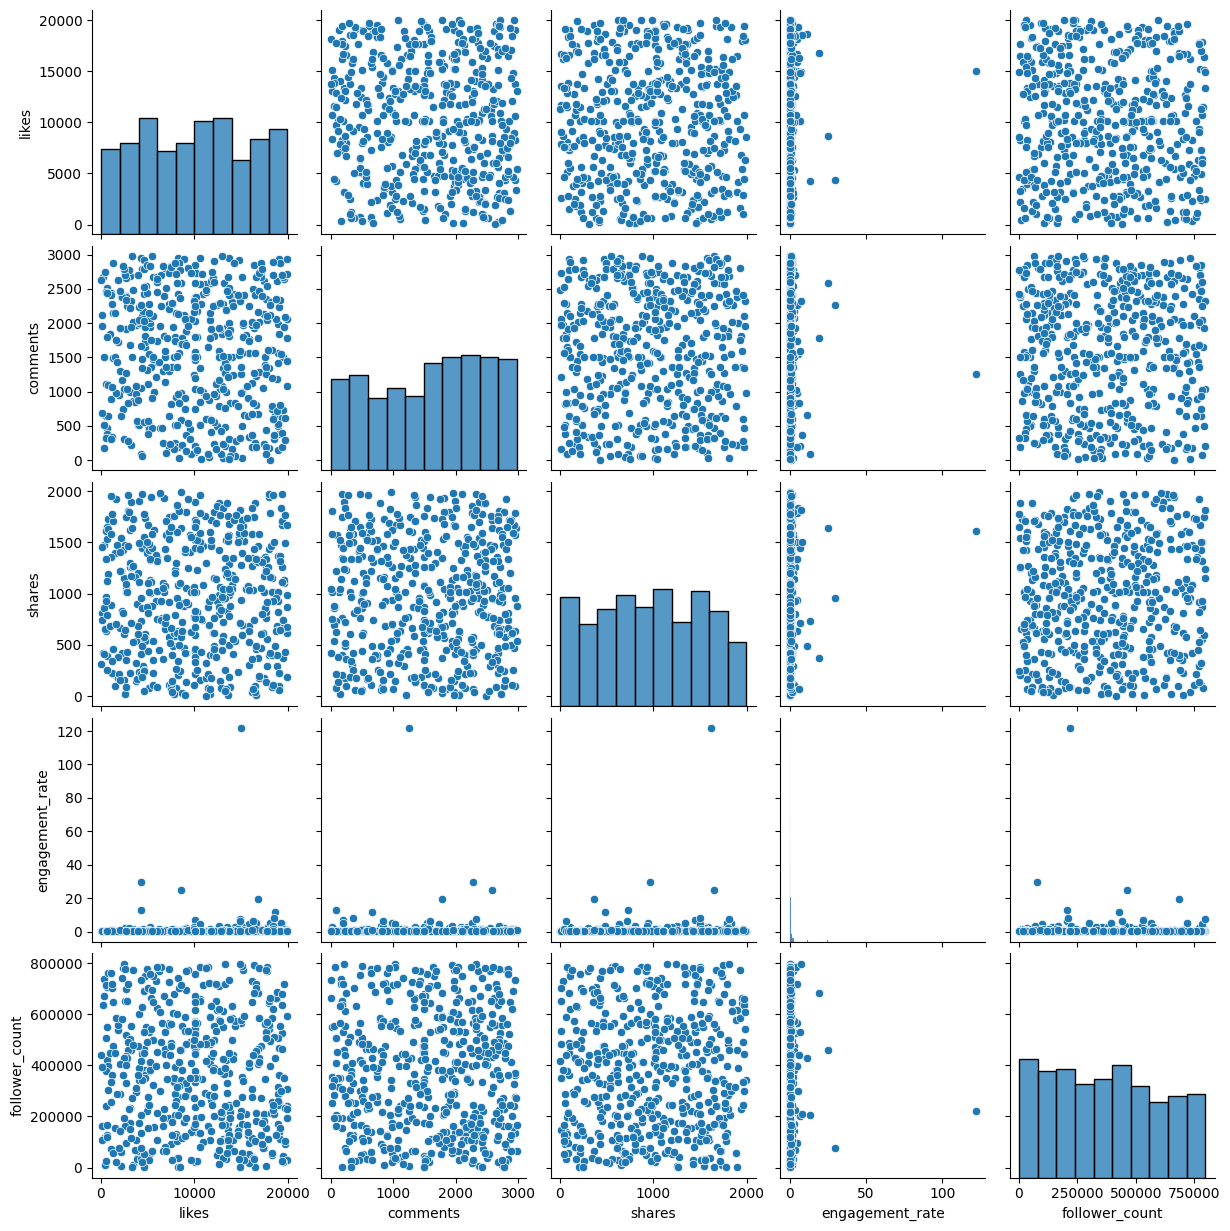

In [ ]:
numeric_cols = [
    "likes",
    "comments",
    "shares",
    "engagement_rate",
    "follower_count"
]

pair_df = df[numeric_cols].dropna()

if len(pair_df) > 500:
    pair_df = pair_df.sample(500, random_state=42)

sns.pairplot(pair_df)
plt.show()

###**Heatmap** — *Correlation matrix*

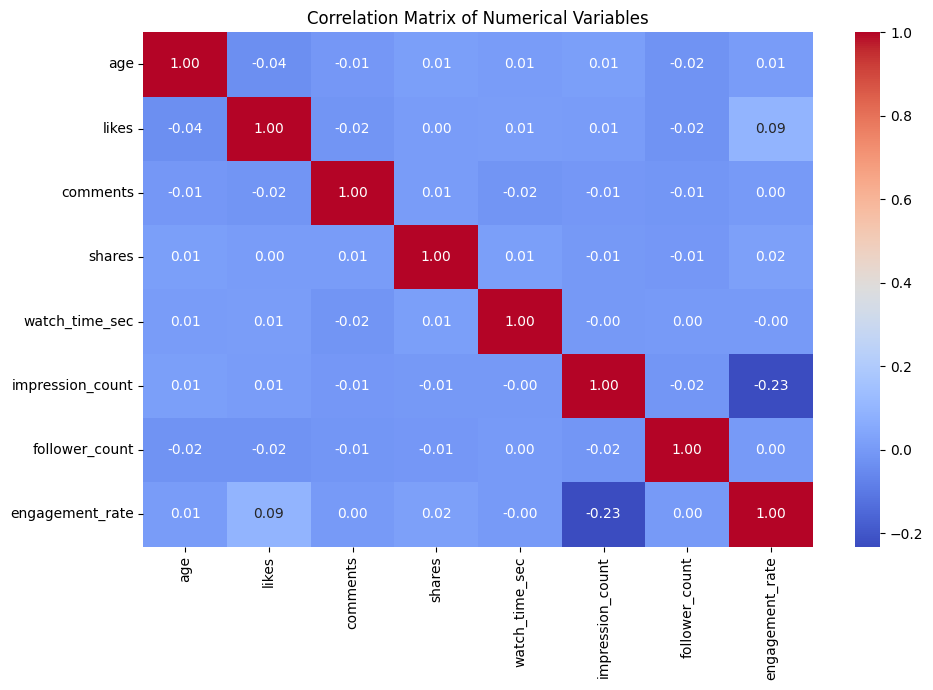

In [ ]:
corr_cols = [
    "age",
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "impression_count",
    "follower_count",
    "engagement_rate"
]

correlation = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

###**Swarm plot** — *Engagement rate by device type*

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning:

18.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning:

39.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning:

36.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning:

27.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning:

46.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.

/usr/local/lib/python3.13/dist-packages/seaborn/categor

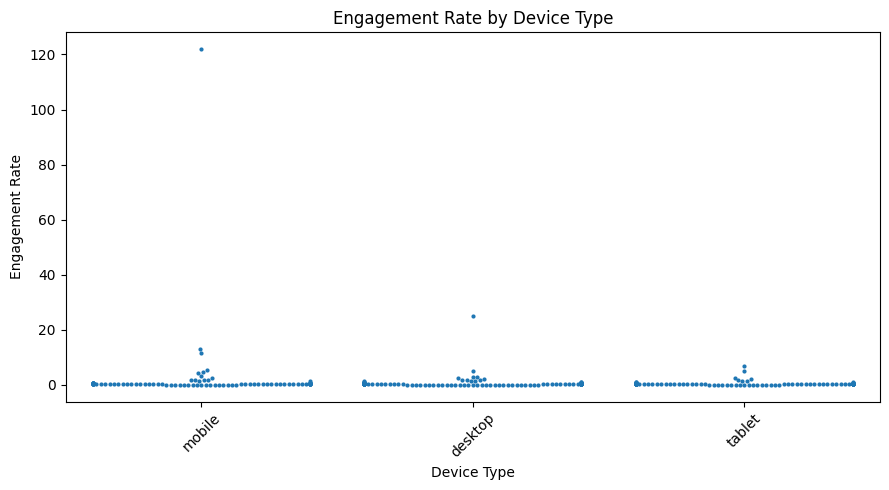

In [ ]:
swarm_df = df[
    ["device_type", "engagement_rate"]
].dropna()

if len(swarm_df) > 300:
    swarm_df = swarm_df.sample(300, random_state=42)

plt.figure(figsize=(9, 5))

sns.swarmplot(
    data=swarm_df,
    x="device_type",
    y="engagement_rate",
    size=3
)

plt.xlabel("Device Type")
plt.ylabel("Engagement Rate")
plt.title("Engagement Rate by Device Type")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##**Plotly interactive visualizations**

###**Interactive line chart — Daily average engagement rate**

In [ ]:
df["posted_at"] = pd.to_datetime(
    df["posted_at"],
    errors="coerce"
)

plotly_df = df.dropna(
    subset=["posted_at", "engagement_rate"]
).copy()

plotly_df["analysis_date"] = (
    plotly_df["posted_at"].dt.date
)

daily_rate = (
    plotly_df.groupby("analysis_date", as_index=False)
    ["engagement_rate"]
    .mean()
)

fig = px.line(
    daily_rate,
    x="analysis_date",
    y="engagement_rate",
    markers=True,
    title="Daily Average Engagement Rate"
)

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Average Engagement Rate"
)

fig.show()

###**Interactive bar chart — Average likes by category**

In [ ]:
category_likes = (
    df.groupby("post_category", as_index=False)
    ["likes"]
    .mean()
    .sort_values("likes", ascending=False)
)

fig = px.bar(
    category_likes,
    x="post_category",
    y="likes",
    title="Interactive Average Likes by Post Category",
    labels={
        "post_category": "Post Category",
        "likes": "Average Likes"
    }
)

fig.show()

###**Interactive bubble chart — Impressions, likes, and comments**

In [ ]:
bubble_df = df.dropna(
    subset=["impression_count", "likes", "comments"]
)

fig = px.scatter(
    bubble_df,
    x="impression_count",
    y="likes",
    size="comments",
    color="post_type",
    hover_data=["post_category", "country"],
    title="Impressions vs Likes and Comments",
    labels={
        "impression_count": "Impressions",
        "likes": "Likes",
        "comments": "Comments"
    }
)

fig.show()

The bubble size represents comments, while the colors distinguish post types.

###**Interactive scatter plot — Followers vs. engagement rate**

In [ ]:
scatter_df = df.dropna(
    subset=["follower_count", "engagement_rate"]
)

fig = px.scatter(
    scatter_df,
    x="follower_count",
    y="engagement_rate",
    color="sentiment",
    hover_data=["post_type", "country"],
    title="Follower Count vs Engagement Rate"
)

fig.show()

#**FINAL INSIGHTS**

##**1. Content Performance**
This identifies the post type with the highest engagement, the best-performing category, and the countries with the highest average engagement rate.

In [ ]:
# 1. Which post types have the highest engagement?
post_type_analysis = (
    df.groupby("post_type")
    .agg(
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_likes=("likes", "mean"),
        total_posts=("post_id", "count")
    )
    .sort_values("avg_engagement_rate", ascending=False)
)

print("Post Type Performance:")
display(post_type_analysis)

# 2. Best-performing content category
category_analysis = (
    df.groupby("post_category")
    .agg(
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_likes=("likes", "mean"),
        total_posts=("post_id", "count")
    )
    .sort_values("avg_engagement_rate", ascending=False)
)

print("Category Performance:")
display(category_analysis)

# 3. Countries with the highest average engagement rate
country_analysis = (
    df.groupby("country")
    .agg(
        avg_engagement_rate=("engagement_rate", "mean"),
        total_posts=("post_id", "count")
    )
    .sort_values("avg_engagement_rate", ascending=False)

)

print("Country Performance:")
display(country_analysis.head(10))

Post Type Performance:


,avg_engagement_rate,avg_likes,total_posts
post_type,,,
video,1.122365,10188.600000,1225
text,1.064549,10100.148193,1245
image,0.895646,10104.865277,1247
reel,0.783047,10037.802416,1283


Category Performance:


,avg_engagement_rate,avg_likes,total_posts
post_category,,,
food,1.358628,10225.522766,593
tech,1.160475,10171.571429,665
lifestyle,1.091019,10180.559308,607
music,0.888803,10205.749606,635
fitness,0.865628,9914.602222,675
education,0.844222,10126.487322,631
fashion,0.807109,9843.356902,594
travel,0.702223,10196.304167,600


Country Performance:


,avg_engagement_rate,total_posts
country,,
Brazil,1.540704,504
Australia,1.324339,493
France,1.146402,496
UAE,1.112352,503
Canada,0.916659,513
UK,0.850966,493
Japan,0.769623,472
Germany,0.759000,490
India,0.655005,535


##**2. User Trends**
This compares engagement across age groups and between verified and non-verified accounts.

In [ ]:
# 4. How age affects engagement
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 17, 25, 35, 45, 60, float("inf")],
    labels=[
        "Under 18",
        "18-25",
        "26-35",
        "36-45",
        "46-60",
        "Above 60"
    ],
    include_lowest=True
)

age_analysis = (
    df.groupby("age_group", observed=True)
    .agg(
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_likes=("likes", "mean"),
        total_posts=("post_id", "count")
    )
    .sort_values("avg_engagement_rate", ascending=False)
)

print("Engagement by Age Group:")
display(age_analysis)

# 5. Performance difference for verified accounts
verified_analysis = (
    df.groupby("is_verified")
    .agg(
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_likes=("likes", "mean"),
        avg_comments=("comments", "mean"),
        total_posts=("post_id", "count")
    )
)

print("Verified vs Non-Verified Accounts:")
display(verified_analysis)

Engagement by Age Group:


,avg_engagement_rate,avg_likes,total_posts
age_group,,,
46-60,1.152669,9796.227601,1384
18-25,1.036932,10139.995283,742
26-35,0.865316,10240.393986,981
Under 18,0.862367,10616.745536,448
36-45,0.860741,10220.458643,1076
Above 60,0.801381,9901.868564,369


Verified vs Non-Verified Accounts:


,avg_engagement_rate,avg_likes,avg_comments,total_posts
is_verified,,,,
False,0.954744,10137.201129,1505.511401,4517
True,1.054250,9824.533126,1469.573499,483


##**3. Behavioral Insights**
This checks which posting hour has the highest average impressions and whether device type is associated with watch time.

In [ ]:
# Ensure posted_at is in datetime format
df["posted_at"] = pd.to_datetime(
    df["posted_at"],
    errors="coerce"
)

# 6. Best time of day for impressions

print(
    "Posting-time analysis cannot be performed because "
    "the dataset contains dates but no actual posting times."
)


# 7. Device type impact on watch time
device_analysis = (
    df.groupby("device_type")
    .agg(
        avg_watch_time=("watch_time_sec", "mean"),
        avg_engagement_rate=("engagement_rate", "mean"),
        total_posts=("post_id", "count")
    )
    .sort_values("avg_watch_time", ascending=False)
)

print("Device Type Performance:")
display(device_analysis)

Posting-time analysis cannot be performed because the dataset contains dates but no actual posting times.
Device Type Performance:


,avg_watch_time,avg_engagement_rate,total_posts
device_type,,,
mobile,4087.830760,1.123999,1684
tablet,3979.736429,0.804560,1658
desktop,3974.792521,0.962006,1658


##**4. Sentiment Analysis**
This compares engagement by sentiment and examines how negative and neutral posts perform.

In [ ]:
# 8. Which sentiment performs best?
sentiment_analysis = (
    df.groupby("sentiment")
    .agg(
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_likes=("likes", "mean"),
        avg_comments=("comments", "mean"),
        avg_shares=("shares", "mean"),
        avg_impressions=("impression_count", "mean"),
        total_posts=("post_id", "count")
    )
    .sort_values("avg_engagement_rate", ascending=False)
)

print("Performance by Sentiment:")
display(sentiment_analysis)

# 9. Behaviour of negative and neutral sentiment posts
negative_neutral = df[
    df["sentiment"].astype(str).str.strip().str.lower()
    .isin(["negative", "neutral"])
]

negative_neutral_analysis = (
    negative_neutral.groupby(
        negative_neutral["sentiment"].astype(str).str.strip().str.lower()
    )
    .agg(
        avg_engagement_rate=("engagement_rate", "mean"),
        avg_likes=("likes", "mean"),
        avg_comments=("comments", "mean"),
        avg_shares=("shares", "mean"),
        avg_impressions=("impression_count", "mean"),
        avg_watch_time=("watch_time_sec", "mean"),
        total_posts=("post_id", "count")
    )
)

print("Negative vs Neutral Posts:")
display(negative_neutral_analysis)

Performance by Sentiment:


,avg_engagement_rate,avg_likes,avg_comments,avg_shares,avg_impressions,total_posts
sentiment,,,,,,
negative,1.038486,10208.096875,1516.094792,1007.307292,50191.960417,960
neutral,0.991170,9923.194499,1528.404060,996.565160,49515.971185,1527
positive,0.919744,10180.062077,1480.650617,1005.086749,50248.107441,2513


Negative vs Neutral Posts:


,avg_engagement_rate,avg_likes,avg_comments,avg_shares,avg_impressions,avg_watch_time,total_posts
sentiment,,,,,,,
negative,1.038486,10208.096875,1516.094792,1007.307292,50191.960417,4054.639583,960
neutral,0.991170,9923.194499,1528.404060,996.565160,49515.971185,4031.823183,1527


# **One-Page Summary: Social Media Engagement Analytics**

## **1. Objective**
The objective of this project is to analyze social media engagement data using Python and identify patterns in content performance, user demographics, account verification, device usage, and audience sentiment. The analysis uses data exploration, statistical summaries, grouping, and visualizations to understand engagement trends.

## **2. Key Findings**

**Content Performance:** Video posts recorded the highest average engagement at approximately 1.122, while the Food category achieved the highest average engagement at approximately 1.359. Brazil recorded the highest average engagement among the countries analyzed, at approximately 1.541. These findings highlight differences in engagement across content types, categories, and countries.

**User Trends:** The 46–60 age group recorded the highest average engagement, at approximately 1.153. Verified accounts also showed higher average engagement (1.054) than non-verified accounts (0.955). These patterns suggest that engagement varies across age groups and account types, although other factors may also influence the results.

**Behavioral Insights:** Mobile users recorded the highest average watch time, at approximately 4,087.83 seconds, compared with tablet and desktop users. However, the best time of day for impressions could not be identified because the dataset contains posting dates but no exact posting times.

**Sentiment Analysis:** Negative-sentiment posts recorded the highest average engagement rate at approximately 1.038, followed by neutral posts at 0.991 and positive posts at 0.920. This indicates that negative-sentiment posts received comparatively higher engagement in the dataset. However, higher engagement does not necessarily represent positive audience perception or better business outcomes.

## **3. Recommendations**

- Prioritize testing video content and topics within the Food category to understand their engagement potential.
- Adapt content strategies to different audience groups and monitor engagement across countries.
- Optimize content for mobile viewing and examine factors that may influence watch time.
- Analyze negative and neutral sentiment alongside comments and shares to understand the nature of audience reactions.
- Collect exact posting timestamps to identify periods associated with higher impressions.

## **4. Conclusion**

The analysis reveals variations in social media engagement across content types, categories, countries, age groups, verification status, devices, and sentiment. These findings can support data-driven content planning and audience analysis. However, the results describe associations within the available dataset and do not establish causation. Further investigation using complete posting timestamps and additional audience information would help produce more actionable insights.